<a href="https://colab.research.google.com/github/HannaVar1/belhard_project/blob/main/02_type_classification_C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from pathlib import Path
import copy
import random

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    LabelEncoder,
)
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)

SEED = 42

NUMERIC_FEATURES = [
    "hp", "attack", "defense",
    "sp_attack", "sp_defense", "speed",
    "height_m", "weight_kg",
]

CATEGORICAL_FEATURES = ["color", "shape"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

TARGET = "type_1"
GROUP = "evolution_chain_id"

PATH = Path(
    "/content/drive/MyDrive/datasets/pokemon_complete.csv"
)

# Загружаем именно сохранённое разбиение эксперимента B.
SPLIT_PATH = Path(
    "/content/drive/MyDrive/classification_results_B/split.csv"
)

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/classification_results_C"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MAX_EPOCHS = 300
PATIENCE = 25
BATCH_SIZE = 32
LEARNING_RATE = 0.001
DEVICE = torch.device("cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

sns.set_theme(style="whitegrid")


def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=150,
        bbox_inches="tight",
    )
    plt.show()
    plt.close()


if not PATH.is_file():
    raise FileNotFoundError(f"Датасет не найден: {PATH}")

raw = pd.read_csv(PATH, encoding="utf-8-sig")

required = [
    "pokedex_number", "name", TARGET, GROUP, *FEATURES
]

missing = set(required) - set(raw.columns)

if missing:
    raise ValueError(f"Отсутствуют столбцы: {sorted(missing)}")

raw["pokedex_number"] = pd.to_numeric(
    raw["pokedex_number"], errors="raise"
)

# Тот же отбор основных записей, что в A и B.
df = raw.loc[
    raw["pokedex_number"].between(1, 1025)
].copy().reset_index(drop=True)

if df.empty or not df["pokedex_number"].is_unique:
    raise ValueError("Пустая выборка или повторяющиеся ID")

if df[[TARGET, GROUP]].isna().any().any():
    raise ValueError("Пропуски в type_1 или evolution_chain_id")

df[TARGET] = df[TARGET].astype(str).str.strip()
df[GROUP] = pd.to_numeric(df[GROUP], errors="raise")

if df[TARGET].eq("").any():
    raise ValueError("Пустые метки типов")

df[NUMERIC_FEATURES] = df[NUMERIC_FEATURES].apply(
    pd.to_numeric, errors="raise"
)

if df[NUMERIC_FEATURES].isna().any().any():
    raise ValueError("Пропуски в числовых признаках")

if not np.isfinite(
    df[NUMERIC_FEATURES].to_numpy(dtype=float)
).all():
    raise ValueError("Бесконечные значения признаков")

if (df[NUMERIC_FEATURES] < 0).any().any():
    raise ValueError("Отрицательные значения признаков")

for column in CATEGORICAL_FEATURES:
    if df[column].isna().any():
        raise ValueError(f"Пропуски в {column}")

    df[column] = df[column].astype(str).str.strip()

    if df[column].eq("").any():
        raise ValueError(f"Пустые категории в {column}")

print("Эксперимент C: MLP с весами классов")
print("Количество объектов:", len(df))
print("Количество типов:", df[TARGET].nunique())

display(df[FEATURES].head())

Эксперимент C: MLP с весами классов
Количество объектов: 1025
Количество типов: 18


,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,color,shape
0,45,49,49,65,65,45,0.7,6.9,green,quadruped
1,60,62,63,80,80,60,1.0,13.0,green,quadruped
2,80,82,83,100,100,80,2.0,100.0,green,quadruped
3,39,52,43,60,50,65,0.6,8.5,red,upright
4,58,64,58,80,65,80,1.1,19.0,red,upright


In [ ]:
if not SPLIT_PATH.is_file():
    raise FileNotFoundError(
        f"Не найден split эксперимента B: {SPLIT_PATH}"
    )

saved_split = pd.read_csv(SPLIT_PATH, encoding="utf-8-sig")

required_split = ["pokedex_number", "split", TARGET, GROUP]
missing = set(required_split) - set(saved_split.columns)

if missing:
    raise ValueError(
        f"В split.csv отсутствуют поля: {sorted(missing)}"
    )

if saved_split[required_split].isna().any().any():
    raise ValueError("В split.csv есть пропуски")

saved_split["pokedex_number"] = pd.to_numeric(
    saved_split["pokedex_number"], errors="raise"
)
saved_split[GROUP] = pd.to_numeric(
    saved_split[GROUP], errors="raise"
)
saved_split[TARGET] = (
    saved_split[TARGET].astype(str).str.strip()
)
saved_split["split"] = (
    saved_split["split"].astype(str).str.strip()
)

if not saved_split["pokedex_number"].is_unique:
    raise ValueError("Повторяющиеся ID в split.csv")

if set(saved_split["split"]) != {
    "train", "validation", "test"
}:
    raise ValueError("Некорректные названия частей выборки")

if set(saved_split["pokedex_number"]) != set(df["pokedex_number"]):
    raise ValueError("Наборы объектов B и C различаются")

reference = saved_split.set_index("pokedex_number")
current = df.set_index("pokedex_number")

for column in [TARGET, GROUP]:
    old = reference[column].reindex(current.index)
    same = old.eq(current[column]).fillna(False)

    if not same.all():
        raise ValueError(
            f"Изменилось поле {column} у ID: "
            f"{current.index[~same].tolist()[:20]}"
        )

assignment = df["pokedex_number"].map(reference["split"])

train = df.loc[assignment == "train"].copy()
val = df.loc[assignment == "validation"].copy()
test = df.loc[assignment == "test"].copy()

parts = {
    "train": train,
    "validation": val,
    "test": test,
}

for first, second in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test"),
]:
    if set(parts[first][GROUP]) & set(parts[second][GROUP]):
        raise ValueError(
            f"Пересечение цепочек: {first}/{second}"
        )

unseen = (
    set(val[TARGET]) | set(test[TARGET])
) - set(train[TARGET])

if unseen:
    raise ValueError(
        f"В train отсутствуют типы: {sorted(unseen)}"
    )

CLASSES = np.array(sorted(train[TARGET].unique()))

summary = pd.DataFrame([
    {
        "split": name,
        "rows": len(part),
        "row_share": len(part) / len(df),
        "chains": part[GROUP].nunique(),
    }
    for name, part in parts.items()
])

counts = pd.DataFrame({
    name: part[TARGET].value_counts()
    for name, part in parts.items()
}).reindex(CLASSES).fillna(0).astype(int)

print("Размеры выборок:")
display(summary.round(3))

print("Представленность типов:")
display(counts)

saved_split.to_csv(
    OUTPUT_DIR / "split.csv",
    index=False,
    encoding="utf-8-sig",
)

Размеры выборок:


,split,rows,row_share,chains
0,train,655,0.639,345
1,validation,170,0.166,87
2,test,200,0.195,109


Представленность типов:


,train,validation,test
type_1,,,
Bug,43,22,18
Dark,37,3,5
Dragon,25,5,7
Electric,33,17,9
Fairy,15,4,10
Fighting,24,6,10
Fire,34,18,14
Flying,7,2,0
Ghost,28,3,4


In [ ]:
def create_preprocessor():
    return ColumnTransformer(
        transformers=[
            (
                "numeric",
                StandardScaler(),
                NUMERIC_FEATURES,
            ),
            (
                "categorical",
                OneHotEncoder(
                    handle_unknown="ignore",
                    sparse_output=False,
                ),
                CATEGORICAL_FEATURES,
            ),
        ],
        sparse_threshold=0,
    )


def calculate_metrics(y_true, prediction):
    return {
        "accuracy": accuracy_score(y_true, prediction),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, prediction
        ),
        "macro_f1": f1_score(
            y_true,
            prediction,
            labels=CLASSES,
            average="macro",
            zero_division=0,
        ),
        "weighted_f1": f1_score(
            y_true,
            prediction,
            average="weighted",
            zero_division=0,
        ),
    }


baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(
    np.zeros((len(train), 1)),
    train[TARGET],
)

svm_models = {}
svm_rows = []

for C in [0.1, 1, 10, 100]:
    for gamma in ["scale", 0.01, 0.1]:
        for class_weight in [None, "balanced"]:
            candidate = make_pipeline(
                create_preprocessor(),
                SVC(
                    kernel="rbf",
                    C=C,
                    gamma=gamma,
                    class_weight=class_weight,
                ),
            )

            candidate.fit(train[FEATURES], train[TARGET])
            prediction = candidate.predict(val[FEATURES])

            score = f1_score(
                val[TARGET],
                prediction,
                labels=CLASSES,
                average="macro",
                zero_division=0,
            )

            key = (float(C), str(gamma), str(class_weight))
            svm_models[key] = candidate

            svm_rows.append({
                "C": C,
                "gamma": str(gamma),
                "class_weight": str(class_weight),
                "validation_macro_f1": score,
            })

svm_results = pd.DataFrame(svm_rows).sort_values(
    "validation_macro_f1",
    ascending=False,
    kind="stable",
)

best_svm_row = svm_results.iloc[0]

svm = svm_models[(
    float(best_svm_row["C"]),
    best_svm_row["gamma"],
    best_svm_row["class_weight"],
)]

print("Лучшие параметры SVM:")
display(best_svm_row.to_frame("value"))

svm_results.to_csv(
    OUTPUT_DIR / "svm_validation_search.csv",
    index=False,
)

Лучшие параметры SVM:


,value
C,10.0
gamma,0.01
class_weight,balanced
validation_macro_f1,0.283008


In [ ]:
# Та же инициализация и порядок обучения, что в B,
# насколько позволяет воспроизводимость среды.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

nn_preprocessor = create_preprocessor()

X_train = nn_preprocessor.fit_transform(
    train[FEATURES]
).astype("float32")

X_val = nn_preprocessor.transform(
    val[FEATURES]
).astype("float32")

encoder = LabelEncoder()
y_train = encoder.fit_transform(train[TARGET])
y_val = encoder.transform(val[TARGET])

input_dim = X_train.shape[1]
num_classes = len(encoder.classes_)

# Порядок весов точно соответствует выходам LabelEncoder.
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(num_classes),
    y=y_train,
)

weights_table = pd.DataFrame({
    "type": encoder.classes_,
    "train_count": np.bincount(
        y_train, minlength=num_classes
    ),
    "loss_weight": class_weights,
})

print("Веса классов — рассчитаны только по train:")
display(weights_table.round(3))

weights_table.to_csv(
    OUTPUT_DIR / "class_weights.csv",
    index=False,
)

train_dataset = TensorDataset(
    torch.from_numpy(X_train),
    torch.tensor(y_train, dtype=torch.long),
)

generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
)

X_val_tensor = torch.from_numpy(X_val).to(DEVICE)
y_val_tensor = torch.tensor(
    y_val,
    dtype=torch.long,
    device=DEVICE,
)

mlp = nn.Sequential(
    nn.Linear(input_dim, 64),
    nn.ReLU(),
    nn.Dropout(0.2),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, num_classes),
).to(DEVICE)

weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=DEVICE,
)

# Единственное изменение обучения MLP относительно B.
criterion = nn.CrossEntropyLoss(weight=weights_tensor)

# Обычная cross-entropy дополнительно:
# позволяет сравнить графики потерь B и C.
unweighted_criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    mlp.parameters(),
    lr=LEARNING_RATE,
)

print("Входной размер MLP:", input_dim)
print("Количество выходных классов:", num_classes)

Веса классов — рассчитаны только по train:


,type,train_count,loss_weight
0,Bug,43,0.846
1,Dark,37,0.983
2,Dragon,25,1.456
3,Electric,33,1.103
4,Fairy,15,2.426
5,Fighting,24,1.516
6,Fire,34,1.070
7,Flying,7,5.198
8,Ghost,28,1.300
9,Grass,62,0.587


Входной размер MLP: 32
Количество выходных классов: 18


Epoch   1 | train weighted loss=2.8906 | val weighted loss=2.8760 | val macro-F1=0.0188
Epoch  20 | train weighted loss=1.9123 | val weighted loss=2.4084 | val macro-F1=0.2709
Epoch  40 | train weighted loss=1.5104 | val weighted loss=2.5573 | val macro-F1=0.2414
Ранняя остановка на эпохе 45
Лучшая эпоха: 20; validation macro-F1: 0.2709


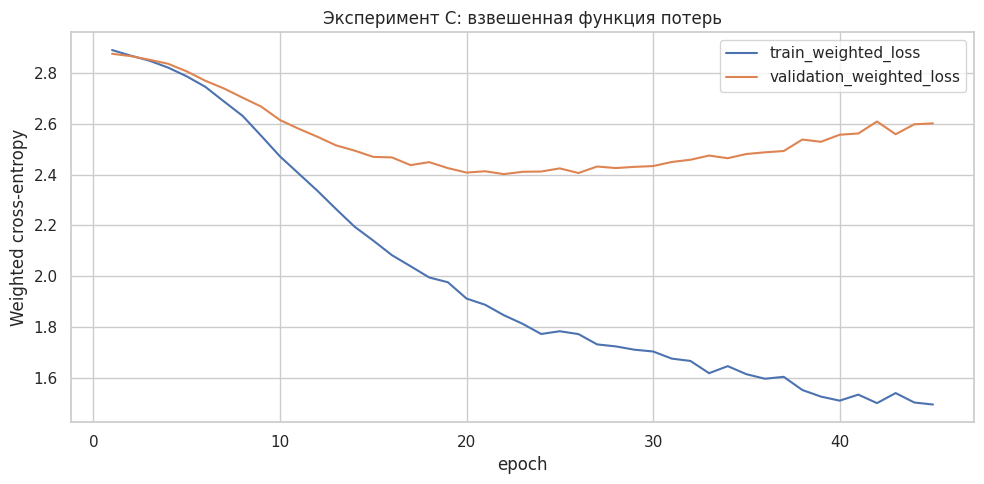

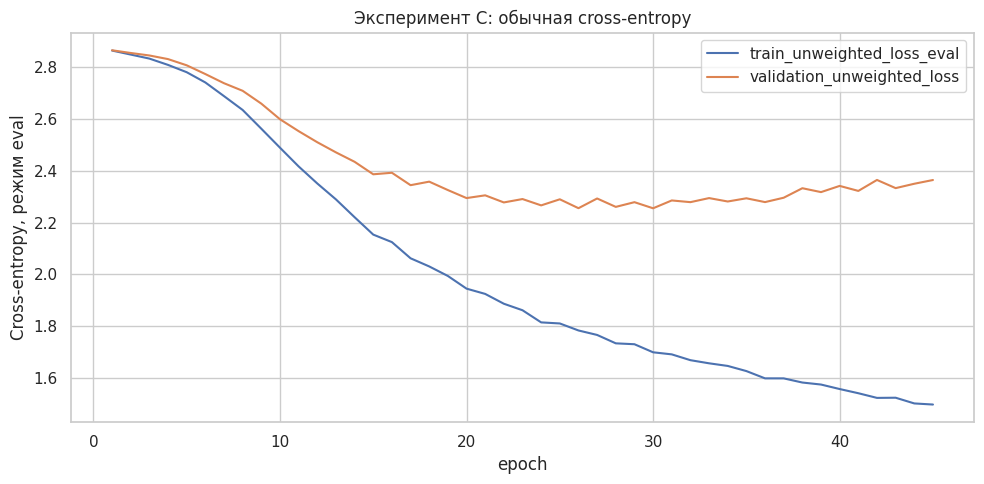

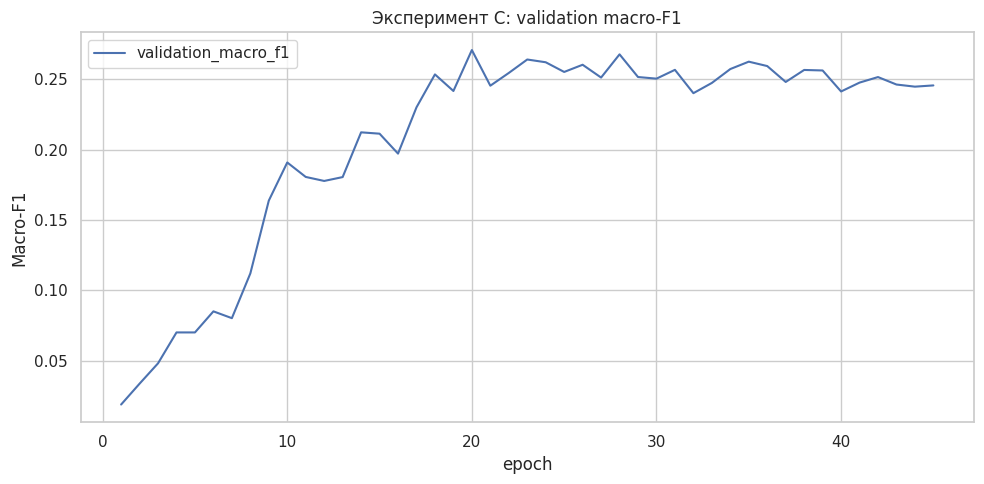

In [ ]:
history_rows = []
best_val_score = -1.0
best_state = None
best_epoch = 0
waiting = 0

for epoch in range(1, MAX_EPOCHS + 1):
    mlp.train()

    weighted_loss_numerator = 0.0
    weighted_loss_denominator = 0.0

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()
        logits = mlp(xb)

        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()

        # Для weighted CrossEntropyLoss с reduction="mean"
        # знаменатель — сумма весов целевых классов батча.
        batch_weight_sum = weights_tensor[yb].sum().item()

        weighted_loss_numerator += (
            loss.item() * batch_weight_sum
        )
        weighted_loss_denominator += batch_weight_sum

    train_weighted_loss = (
        weighted_loss_numerator
        / weighted_loss_denominator
    )

    mlp.eval()

    with torch.no_grad():
        val_logits = mlp(X_val_tensor)

        val_weighted_loss = criterion(
            val_logits, y_val_tensor
        ).item()

        val_unweighted_loss = unweighted_criterion(
            val_logits, y_val_tensor
        ).item()

        # Обычная train loss в режиме eval:
        # отдельно от батчевой loss во время обучения.
        train_logits = mlp(
            torch.from_numpy(X_train).to(DEVICE)
        )
        train_unweighted_loss = unweighted_criterion(
            train_logits,
            torch.tensor(
                y_train,
                dtype=torch.long,
                device=DEVICE,
            ),
        ).item()

        predicted_ids = (
            val_logits.argmax(dim=1).cpu().numpy()
        )

    val_score = f1_score(
        y_val,
        predicted_ids,
        labels=np.arange(num_classes),
        average="macro",
        zero_division=0,
    )

    history_rows.append({
        "epoch": epoch,
        "train_weighted_loss": train_weighted_loss,
        "validation_weighted_loss": val_weighted_loss,
        "train_unweighted_loss_eval": train_unweighted_loss,
        "validation_unweighted_loss": val_unweighted_loss,
        "validation_macro_f1": val_score,
    })

    if val_score > best_val_score:
        best_val_score = val_score
        best_state = copy.deepcopy(mlp.state_dict())
        best_epoch = epoch
        waiting = 0
    else:
        waiting += 1

    if epoch == 1 or epoch % 20 == 0:
        print(
            f"Epoch {epoch:3d} | "
            f"train weighted loss={train_weighted_loss:.4f} | "
            f"val weighted loss={val_weighted_loss:.4f} | "
            f"val macro-F1={val_score:.4f}"
        )

    if waiting >= PATIENCE:
        print(f"Ранняя остановка на эпохе {epoch}")
        break

mlp.load_state_dict(best_state)
mlp.eval()

print(
    f"Лучшая эпоха: {best_epoch}; "
    f"validation macro-F1: {best_val_score:.4f}"
)

history = pd.DataFrame(history_rows)
history.to_csv(
    OUTPUT_DIR / "mlp_history.csv",
    index=False,
)

history.plot(
    x="epoch",
    y=["train_weighted_loss", "validation_weighted_loss"],
    figsize=(10, 5),
)
plt.title("Эксперимент C: взвешенная функция потерь")
plt.ylabel("Weighted cross-entropy")
save_plot("mlp_weighted_loss.png")

history.plot(
    x="epoch",
    y=[
        "train_unweighted_loss_eval",
        "validation_unweighted_loss",
    ],
    figsize=(10, 5),
)
plt.title("Эксперимент C: обычная cross-entropy")
plt.ylabel("Cross-entropy, режим eval")
save_plot("mlp_unweighted_loss.png")

history.plot(
    x="epoch",
    y="validation_macro_f1",
    figsize=(10, 5),
)
plt.title("Эксперимент C: validation macro-F1")
plt.ylabel("Macro-F1")
save_plot("mlp_validation_f1.png")

In [ ]:
def predict_mlp(part):
    X = nn_preprocessor.transform(
        part[FEATURES]
    ).astype("float32")

    mlp.eval()

    with torch.no_grad():
        logits = mlp(torch.from_numpy(X).to(DEVICE))
        predicted_ids = (
            logits.argmax(dim=1).cpu().numpy()
        )

    return encoder.inverse_transform(predicted_ids)


def predict_models(part):
    return {
        "Dummy": baseline.predict(
            np.zeros((len(part), 1))
        ),
        "SVM RBF": svm.predict(part[FEATURES]),
        "PyTorch MLP": predict_mlp(part),
    }


metric_rows = []
validation_predictions = None

for split_name, part in {
    "train": train,
    "validation": val,
}.items():
    predictions = predict_models(part)

    if split_name == "validation":
        validation_predictions = predictions

    for model_name, prediction in predictions.items():
        metric_rows.append({
            "split": split_name,
            "model": model_name,
            **calculate_metrics(part[TARGET], prediction),
        })

metrics_C = pd.DataFrame(metric_rows)

print("Эксперимент C: train и validation")
display(metrics_C.round(4))

metrics_C.to_csv(
    OUTPUT_DIR / "train_validation_metrics.csv",
    index=False,
)

# Фактические validation-метрики B из присланного отчёта.
metrics_B = pd.DataFrame([
    {
        "model": "Dummy",
        "accuracy_B": 0.10588235294117647,
        "balanced_accuracy_B": 0.05555555555555555,
        "macro_f1_B": 0.010638297872340425,
        "weighted_f1_B": 0.02027534418022528,
    },
    {
        "model": "SVM RBF",
        "accuracy_B": 0.34705882352941175,
        "balanced_accuracy_B": 0.3105558384970149,
        "macro_f1_B": 0.28300845759179094,
        "weighted_f1_B": 0.3789949707155589,
    },
    {
        "model": "PyTorch MLP",
        "accuracy_B": 0.4117647058823529,
        "balanced_accuracy_B": 0.3323852436597534,
        "macro_f1_B": 0.2844729835593847,
        "weighted_f1_B": 0.4115119102871976,
    },
])

validation_C = metrics_C.loc[
    metrics_C["split"] == "validation"
].drop(columns="split").rename(columns={
    "accuracy": "accuracy_C",
    "balanced_accuracy": "balanced_accuracy_C",
    "macro_f1": "macro_f1_C",
    "weighted_f1": "weighted_f1_C",
})

comparison = metrics_B.merge(validation_C, on="model")

for metric in [
    "accuracy", "balanced_accuracy", "macro_f1", "weighted_f1"
]:
    comparison[f"{metric}_change"] = (
        comparison[f"{metric}_C"]
        - comparison[f"{metric}_B"]
    )

print("Сравнение B и C на validation:")
display(comparison.round(4))

comparison.to_csv(
    OUTPUT_DIR / "comparison_B_C.csv",
    index=False,
)

# SVM и Dummy не изменялись — проверяем контрольные результаты.
for model_name in ["Dummy", "SVM RBF"]:
    row = comparison.loc[
        comparison["model"] == model_name
    ].iloc[0]

    if not np.isclose(
        row["macro_f1_B"],
        row["macro_f1_C"],
        atol=1e-8,
        rtol=0,
    ):
        print(
            f"Внимание: результат {model_name} отличается от B. "
            "Проверьте данные, разбиение, сетку параметров "
            "и версии библиотек."
        )

candidates = validation_C.loc[
    validation_C["model"] != "Dummy"
]

recommended_model_C = candidates.sort_values(
    "macro_f1_C",
    ascending=False,
    kind="stable",
).iloc[0]["model"]

print(
    "Рекомендуемая модель внутри эксперимента C:",
    recommended_model_C,
)

Эксперимент C: train и validation


,split,model,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,train,Dummy,0.1298,0.0556,0.0128,0.0298
1,train,SVM RBF,0.5405,0.5907,0.5294,0.5413
2,train,PyTorch MLP,0.4290,0.4681,0.3965,0.4173
3,validation,Dummy,0.1059,0.0556,0.0106,0.0203
4,validation,SVM RBF,0.3471,0.3106,0.2830,0.3790
5,validation,PyTorch MLP,0.3941,0.2613,0.2709,0.4277


Сравнение B и C на validation:


,model,accuracy_B,balanced_accuracy_B,macro_f1_B,weighted_f1_B,accuracy_C,balanced_accuracy_C,macro_f1_C,weighted_f1_C,accuracy_change,balanced_accuracy_change,macro_f1_change,weighted_f1_change
0,Dummy,0.1059,0.0556,0.0106,0.0203,0.1059,0.0556,0.0106,0.0203,0.0000,0.0000,0.0000,0.0000
1,SVM RBF,0.3471,0.3106,0.2830,0.3790,0.3471,0.3106,0.2830,0.3790,0.0000,0.0000,0.0000,0.0000
2,PyTorch MLP,0.4118,0.3324,0.2845,0.4115,0.3941,0.2613,0.2709,0.4277,-0.0176,-0.0711,-0.0136,0.0162


Рекомендуемая модель внутри эксперимента C: SVM RBF



validation: Dummy


,precision,recall,f1-score,support
Bug,0.000,0.0,0.000,22.0
Dark,0.000,0.0,0.000,3.0
Dragon,0.000,0.0,0.000,5.0
Electric,0.000,0.0,0.000,17.0
Fairy,0.000,0.0,0.000,4.0
Fighting,0.000,0.0,0.000,6.0
Fire,0.000,0.0,0.000,18.0
Flying,0.000,0.0,0.000,2.0
Ghost,0.000,0.0,0.000,3.0
Grass,0.000,0.0,0.000,21.0


Ошибок: 152 из 170


,pokedex_number,name,evolution_chain_id,type_1,hp,attack,defense,sp_attack,sp_defense,speed,height_m,weight_kg,color,shape,prediction,correct
22,23,Ekans,9,Poison,35,60,44,40,54,55,2.0,6.9,purple,squiggle,Water,False
23,24,Arbok,9,Poison,60,95,69,65,79,80,3.5,65.0,purple,squiggle,Water,False
42,43,Oddish,18,Grass,45,50,55,75,65,30,0.5,5.4,blue,legs,Water,False
43,44,Gloom,18,Grass,60,65,70,85,75,40,0.8,8.6,blue,humanoid,Water,False
44,45,Vileplume,18,Grass,75,80,85,110,90,50,1.2,18.6,red,humanoid,Water,False
47,48,Venonat,20,Bug,60,55,50,40,55,45,1.0,30.0,purple,humanoid,Water,False
48,49,Venomoth,20,Bug,70,65,60,90,75,90,1.5,12.5,purple,bug-wings,Water,False
65,66,Machop,28,Fighting,70,80,50,35,35,35,0.8,19.5,gray,upright,Water,False
66,67,Machoke,28,Fighting,80,100,70,50,60,45,1.5,70.5,gray,humanoid,Water,False
67,68,Machamp,28,Fighting,90,130,80,65,85,55,1.6,130.0,gray,humanoid,Water,False


Самые частые пары ошибок:


,,count
type_1,prediction,
Bug,Water,22
Grass,Water,21
Fire,Water,18
Electric,Water,17
Normal,Water,14
Poison,Water,11
Steel,Water,9
Rock,Water,7
Fighting,Water,6


... (16 outputs left out)

Количество предсказаний каждого типа:


,predicted_count
Bug,15
Dark,3
Dragon,4
Electric,11
Fairy,7
Fighting,15
Fire,19
Flying,3
Ghost,7
Grass,17


Изменение F1 каждого типа для MLP:


,F1_B,F1_C,support,change
Bug,0.615,0.703,22.0,0.087
Dark,0.000,0.000,3.0,0.000
Dragon,0.333,0.222,5.0,-0.111
Electric,0.400,0.500,17.0,0.100
Fairy,0.000,0.000,4.0,0.000
Fighting,0.375,0.381,6.0,0.006
Fire,0.516,0.541,18.0,0.024
Flying,0.000,0.000,2.0,0.000
Ghost,0.000,0.000,3.0,0.000
Grass,0.537,0.526,21.0,-0.010


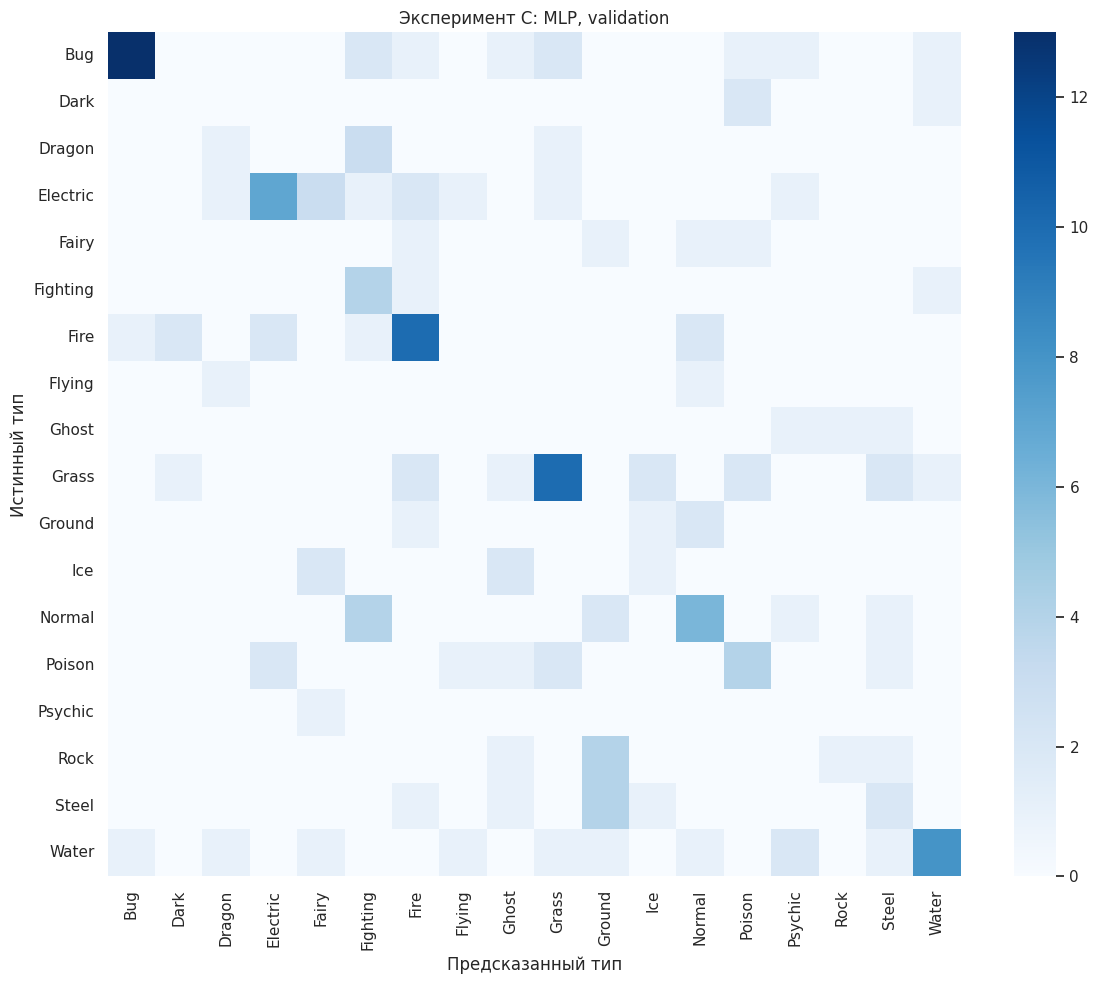

In [ ]:
def analyze_predictions(part, predictions, split_name):
    reports = {}

    for model_name, prediction in predictions.items():
        safe_name = model_name.lower().replace(" ", "_")

        print("\n" + "=" * 60)
        print(f"{split_name}: {model_name}")

        report = pd.DataFrame(
            classification_report(
                part[TARGET],
                prediction,
                labels=CLASSES,
                output_dict=True,
                zero_division=0,
            )
        ).T

        reports[model_name] = report

        display(
            report.loc[
                CLASSES,
                ["precision", "recall", "f1-score", "support"],
            ].round(3)
        )

        prediction_table = part[
            ["pokedex_number", "name", GROUP, TARGET, *FEATURES]
        ].copy()

        prediction_table["prediction"] = prediction
        prediction_table["correct"] = (
            prediction_table[TARGET]
            == prediction_table["prediction"]
        )

        errors = prediction_table.loc[
            ~prediction_table["correct"]
        ]

        print(f"Ошибок: {len(errors)} из {len(part)}")
        display(errors.head(15))

        pairs = (
            errors.groupby([TARGET, "prediction"])
            .size()
            .sort_values(ascending=False)
            .rename("count")
        )

        print("Самые частые пары ошибок:")
        display(pairs.head(10).to_frame())

        print("Количество предсказаний каждого типа:")
        display(
            pd.Series(prediction)
            .value_counts()
            .reindex(CLASSES, fill_value=0)
            .to_frame("predicted_count")
        )

        report.to_csv(
            OUTPUT_DIR / f"{split_name}_{safe_name}_report.csv",
            encoding="utf-8-sig",
        )

        prediction_table.to_csv(
            OUTPUT_DIR / f"{split_name}_{safe_name}_predictions.csv",
            index=False,
            encoding="utf-8-sig",
        )

        pairs.to_csv(
            OUTPUT_DIR / f"{split_name}_{safe_name}_error_pairs.csv",
            encoding="utf-8-sig",
        )

    return reports


reports_C = analyze_predictions(
    val,
    validation_predictions,
    "validation",
)

# Сравнение классов MLP B и C по присланным результатам B.
f1_B = pd.Series({
    "Bug": 0.6153846153846154,
    "Dark": 0.0,
    "Dragon": 0.3333333333333333,
    "Electric": 0.4,
    "Fairy": 0.0,
    "Fighting": 0.375,
    "Fire": 0.5161290322580645,
    "Flying": 0.0,
    "Ghost": 0.0,
    "Grass": 0.5365853658536586,
    "Ground": 0.2,
    "Ice": 0.0,
    "Normal": 0.4166666666666667,
    "Poison": 0.3,
    "Psychic": 0.14285714285714285,
    "Rock": 0.6153846153846154,
    "Steel": 0.14285714285714285,
    "Water": 0.5263157894736842,
}, name="F1_B")

mlp_report_C = reports_C["PyTorch MLP"].loc[CLASSES]

class_comparison = pd.concat([
    f1_B,
    mlp_report_C["f1-score"].rename("F1_C"),
    mlp_report_C["support"],
], axis=1)

class_comparison["change"] = (
    class_comparison["F1_C"] - class_comparison["F1_B"]
)

print("Изменение F1 каждого типа для MLP:")
display(class_comparison.round(3))

class_comparison.to_csv(
    OUTPUT_DIR / "mlp_class_comparison_B_C.csv",
    encoding="utf-8-sig",
)

matrix = confusion_matrix(
    val[TARGET],
    validation_predictions["PyTorch MLP"],
    labels=CLASSES,
)

plt.figure(figsize=(12, 10))
sns.heatmap(
    matrix,
    xticklabels=CLASSES,
    yticklabels=CLASSES,
    cmap="Blues",
)
plt.title("Эксперимент C: MLP, validation")
plt.xlabel("Предсказанный тип")
plt.ylabel("Истинный тип")
plt.xticks(rotation=90)
plt.yticks(rotation=0)

save_plot("validation_mlp_confusion_matrix.png")

In [ ]:
joblib.dump(
    {
        "baseline": baseline,
        "svm": svm,
        "mlp_preprocessor": nn_preprocessor,
        "label_encoder": encoder,
        "features": FEATURES,
        "numeric_features": NUMERIC_FEATURES,
        "categorical_features": CATEGORICAL_FEATURES,
        "target": TARGET,
        "class_weights": class_weights,
        "recommended_model_C": recommended_model_C,
    },
    OUTPUT_DIR / "classification_models.joblib",
)

torch.save(
    {
        "state_dict": mlp.state_dict(),
        "input_dim": input_dim,
        "num_classes": num_classes,
        "classes": encoder.classes_.tolist(),
        "class_weights": class_weights.tolist(),
        "features": FEATURES,
        "best_epoch": best_epoch,
        "seed": SEED,
    },
    OUTPUT_DIR / "mlp_checkpoint.pt",
)

# Пока выбираем между B и C, оставляем False.
RUN_TEST = False

if RUN_TEST:
    # Выполнять только после фиксации окончательного протокола.
    # Этот блок оценивает модели C, а не выбирает между B и C.
    test_predictions = predict_models(test)

    test_metrics = pd.DataFrame([
        {
            "model": name,
            **calculate_metrics(test[TARGET], prediction),
        }
        for name, prediction in test_predictions.items()
    ])

    display(test_metrics.round(4))

    test_metrics.to_csv(
        OUTPUT_DIR / "test_metrics.csv",
        index=False,
    )

    analyze_predictions(test, test_predictions, "test")
else:
    print("Test не оценивался.")

print("Результаты сохранены:", OUTPUT_DIR)

Test не оценивался.
Результаты сохранены: /content/drive/MyDrive/classification_results_C
